# 02 · AES TVLA (Test Vector Leakage Assessment)

**Goal:** Check whether power traces from a **fixed plaintext** and **random plaintexts** differ statistically at any sample time.

**Inputs:** The two CSV files created by Notebook 01. **No hardware connection is required.**

**Method:** First-order fixed-vs-random TVLA using **Welch's two-sample t-test** at every sample, with the original threshold **±4.5**.

## Step 1 — Imports and file settings

Run from the folder containing your captured CSV files. You can reduce `TRACES_PER_GROUP` for a quick trial; `None` uses **all** rows. Large datasets require substantial RAM with the straightforward method used here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

FIXED_CSV = "custom_aes_traces_fixed.csv"
RANDOM_CSV = "custom_aes_traces_random.csv"
TRACES_PER_GROUP = None     # None = all captured traces
TVLA_THRESHOLD = 4.5

for filename in (FIXED_CSV, RANDOM_CSV):
    if not Path(filename).exists():
        raise FileNotFoundError(f"Cannot find {filename}; run Notebook 01 first.")

## Step 2 — Load only the waveform samples

The first two columns (`plaintext` and `ciphertext`) are metadata, so they are excluded from the statistical test. A matrix has shape **(number of traces, samples per trace)**.

In [2]:
def load_samples(csv_file, nrows=None):
    """Read sample columns as float32 to save memory."""
    sample_columns = pd.read_csv(csv_file, nrows=0).columns.tolist()[2:]
    if not sample_columns:
        raise ValueError(f"No waveform columns found in {csv_file}")
    return pd.read_csv(
        csv_file, usecols=sample_columns, nrows=nrows, dtype=np.float32
    ).to_numpy()


fixed_traces = load_samples(FIXED_CSV, TRACES_PER_GROUP)
random_traces = load_samples(RANDOM_CSV, TRACES_PER_GROUP)

if fixed_traces.shape[1] != random_traces.shape[1]:
    raise ValueError("Fixed and random traces have different sample counts.")
if min(len(fixed_traces), len(random_traces)) < 2:
    raise ValueError("At least two traces are needed in each group.")

print("Fixed traces :", fixed_traces.shape)
print("Random traces:", random_traces.shape)

Fixed traces : (10000, 5000)
Random traces: (10000, 5000)


## Step 3 — Calculate Welch's t-statistic

For each sample index \(j\), compare the two groups:

\[
t_j = \frac{\overline{x}_{\mathrm{fixed},j}-\overline{x}_{\mathrm{random},j}}
{\sqrt{s_{\mathrm{fixed},j}^2/n_{\mathrm{fixed}}+s_{\mathrm{random},j}^2/n_{\mathrm{random}}}}.
\]

`scipy.stats.ttest_ind(..., equal_var=False)` does this for all sample positions at once (same approach as the original notebook).

In [3]:
t_values, p_values = stats.ttest_ind(
    fixed_traces,
    random_traces,
    axis=0,              # compare each time sample across many traces
    equal_var=False,     # Welch's t-test
)

# A sample that is constant in both groups can produce NaN (undefined t).
valid = ~np.isnan(t_values)
if not np.any(valid):
    raise RuntimeError("Every t-value is undefined. Check the capture data.")

max_abs_t = float(np.max(np.abs(t_values[valid])))
max_index = int(np.nanargmax(np.abs(t_values)))
leakage_detected = bool(max_abs_t > TVLA_THRESHOLD)

print(f"Maximum |t| : {max_abs_t:.3f} at sample {max_index}")
print(f"Threshold   : ±{TVLA_THRESHOLD}")
print("Result      :", "Leakage detected" if leakage_detected else "No leakage detected by this test")
print("Undefined t-values:", int(np.isnan(t_values).sum()))

Maximum |t| : 78.609 at sample 1130
Threshold   : ±4.5
Result      : Leakage detected
Undefined t-values: 0


## Step 4 — Plot the TVLA result

A curve crossing either threshold indicates statistically detectable **data-dependent behavior** in this measurement. Remaining between the lines does **not** prove that an implementation is side-channel secure.

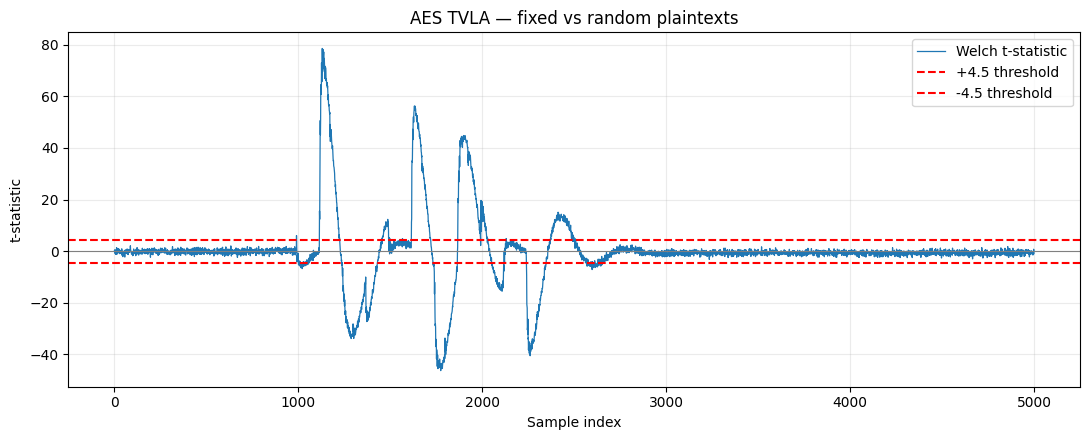

In [4]:
plt.figure(figsize=(11, 4.5))
plt.plot(t_values, linewidth=0.9, label="Welch t-statistic")
plt.axhline(+TVLA_THRESHOLD, color="red", linestyle="--", label="+4.5 threshold")
plt.axhline(-TVLA_THRESHOLD, color="red", linestyle="--", label="-4.5 threshold")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("AES TVLA — fixed vs random plaintexts")
plt.xlabel("Sample index")
plt.ylabel("t-statistic")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

### Next

A TVLA threshold crossing is a leakage **detection** result; it does not by itself recover the key. Run **03 · AES CPA** to test whether the measured traces support AES-128 key recovery.